# 예측모델 제작 과제 - 포켓몬 데이터

- 이름 : 이우진
- 선택한 문제 : **문제 [2] 전설 포켓몬 여부(`isLegendary`) 예측 (분류)**
- 데이터 : `pokemon_alopez247.csv` (포켓몬 721마리, 23개 컬럼)

---
## 해결 과제 (공통)

### 1. `pandas`를 사용하여 `pokemon_alopez247.csv` 파일 데이터를 불러와 `DataFrame`으로 저장하시오.

In [1]:
import pandas as pd

df = pd.read_csv("pokemon_alopez247.csv")

pd.set_option("display.max_columns", None)

print(df.shape)

(721, 23)


### 2. 저장된 데이터에서 상위 5개 행을 출력하시오.

In [2]:
df.head()


,Number,Name,Type_1,Type_2,Total,HP,Attack,Defense,Sp_Atk,Sp_Def,Speed,Generation,isLegendary,Color,hasGender,Pr_Male,Egg_Group_1,Egg_Group_2,hasMegaEvolution,Height_m,Weight_kg,Catch_Rate,Body_Style
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False,Green,True,0.875,Monster,Grass,False,0.71,6.9,45,quadruped
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False,Green,True,0.875,Monster,Grass,False,0.99,13.0,45,quadruped
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False,Green,True,0.875,Monster,Grass,True,2.01,100.0,45,quadruped
3,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False,Red,True,0.875,Monster,Dragon,False,0.61,8.5,45,bipedal_tailed
4,5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80,1,False,Red,True,0.875,Monster,Dragon,False,1.09,19.0,45,bipedal_tailed


### 3. 각 열의 이름, 결측치 여부, 데이터 타입(`dtype`)을 한 번에 확인하시오.

`df.info()`를 실행한 후, 출력 결과를 바탕으로 다음을 기술하시오.
- 결측치가 존재하는 열과 결측 개수
- 각 열의 결측이 **무엇을 의미하는지** (위 데이터 설명 참고)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 721 entries, 0 to 720
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Number            721 non-null    int64  
 1   Name              721 non-null    str    
 2   Type_1            721 non-null    str    
 3   Type_2            350 non-null    str    
 4   Total             721 non-null    int64  
 5   HP                721 non-null    int64  
 6   Attack            721 non-null    int64  
 7   Defense           721 non-null    int64  
 8   Sp_Atk            721 non-null    int64  
 9   Sp_Def            721 non-null    int64  
 10  Speed             721 non-null    int64  
 11  Generation        721 non-null    int64  
 12  isLegendary       721 non-null    bool   
 13  Color             721 non-null    str    
 14  hasGender         721 non-null    bool   
 15  Pr_Male           644 non-null    float64
 16  Egg_Group_1       721 non-null    str    
 17  Egg_Grou

**결측치가 존재하는 열과 결측 개수는 다음과 같습니다.**

| 열 | Non-Null | 결측 개수 |
|---|---|---|
| `Type_2` | 350 | 371 |
| `Pr_Male` | 644 | 77 |
| `Egg_Group_2` | 191 | 530 |

**각 열의 결측이 의미하는 것은 다음과 같습니다.**

- `Type_2` : 보조 타입이 **없는** 포켓몬입니다. (타입이 하나뿐입니다.)
- `Pr_Male` : 성별 구분이 **없는** 포켓몬입니다. (`hasGender`가 False인 77마리와 정확히 일치합니다.)
- `Egg_Group_2` : 두 번째 알 그룹이 **없는** 포켓몬입니다.

→ 세 열 모두 값을 몰라서 비어 있는 것이 아니라, **"해당 사항 없음"을 뜻하는 결측**입니다.

### 4. 결측치를 처리하시오.

- 처리 방식은 자유롭게 선택해도 됩니다. (예: `fillna()`로 `'None'` 또는 특정 숫자 채우기)
- **왜 그렇게 처리했는지 한 줄로 기술**하시오.
- 처리 후 전체 결측치 개수가 0인지 확인하시오.

In [4]:
# 범주형 : 보조 타입, 두 번째 알 그룹이 없는 경우이므로 "None"이라는 하나의 범주로 채웁니다.
df["Type_2"] = df["Type_2"].fillna("None")
df["Egg_Group_2"] = df["Egg_Group_2"].fillna("None")

# 수치형 : 성별이 없는 포켓몬이므로 확률(0~1)에 없는 값인 -1로 채워 구분합니다.
df["Pr_Male"] = df["Pr_Male"].fillna(-1)

print("전체 결측치 개수 :", df.isna().sum().sum())

전체 결측치 개수 : 0


**결측치 처리 방법과 이유 (한 줄 요약)** : 세 열의 결측은 값을 모르는 것이 아니라 "해당 없음"을 뜻하기 때문에, 범주형(`Type_2`, `Egg_Group_2`)은 `"None"` 범주로, 수치형(`Pr_Male`)은 확률 범위(0~1)에 없는 `-1`로 채워 "없음" 자체를 정보로 남겼습니다.

**자세한 설명**

1. **결측의 의미** : 이 데이터의 결측은 값을 기록하지 못해서 비어 있는 것이 아니라, 원래 값이 없어서 비어 있는 것입니다. 예를 들어 파이리는 타입이 불꽃 하나뿐이라 `Type_2`가 비어 있고, 성별이 없는 포켓몬은 "수컷일 확률" 자체가 없기 때문에 `Pr_Male`이 비어 있습니다. 따라서 평균값으로 채우거나 행을 삭제하는 방법은 맞지 않다고 판단했습니다. (행을 삭제하면 `Egg_Group_2` 때문에 721마리 중 530마리가 사라집니다.)

2. **범주형 (`Type_2`, `Egg_Group_2`)** : 빈칸에 `"None"`이라는 값을 넣어 "보조 타입 없음", "두 번째 알 그룹 없음"을 하나의 범주로 만들었습니다. 원-핫 인코딩을 하면 `Type_2_None` 같은 열이 생기기 때문에, 모델이 "보조 타입이 없는 포켓몬"이라는 정보도 학습할 수 있습니다.

3. **수치형 (`Pr_Male`)** : 숫자 컬럼이라 글자를 넣을 수 없기 때문에, 확률(0~1)로는 나올 수 없는 값인 `-1`로 채웠습니다. 0.5는 수컷일 확률 50%, 0은 항상 암컷을 뜻하지만 `-1`은 "성별 자체가 없음"을 뜻하므로 다른 값과 헷갈리지 않습니다. 만약 평균(약 0.55)으로 채웠다면 성별이 없는 포켓몬이 "수컷일 확률 55%"인 포켓몬처럼 바뀌어 버립니다.

4. **"없음"을 정보로 남긴 이유** : 전설 포켓몬은 성별이 없는 경우가 많기 때문에, "성별이 없다"는 사실 자체가 전설 여부를 예측하는 데 도움이 되는 정보입니다. 결측을 지우거나 엉뚱한 값으로 채우면 이 정보가 사라지므로, "없음"이 그대로 드러나도록 처리했습니다.

### 5. 전설 포켓몬(`isLegendary`=`True`)과 일반 포켓몬이 각각 몇 마리인지, 전설 포켓몬의 비율(%)은 얼마인지 계산하시오.

In [5]:
counts = df["isLegendary"].value_counts()

legend_table = pd.DataFrame({
    "구분": ["일반 포켓몬", "전설 포켓몬"],
    "마리 수": [counts[False], counts[True]],
    "비율(%)": [counts[False] / len(df) * 100, counts[True] / len(df) * 100],
}).round(2)

display(legend_table)

,구분,마리 수,비율(%)
0,일반 포켓몬,675,93.62
1,전설 포켓몬,46,6.38


---
## 해결 과제 (선택) - 문제 [2] 전설 포켓몬 여부(`isLegendary`) 예측 (분류)

능력치와 속성 정보로 포켓몬이 전설인지 아닌지 맞히는 분류 모델을 만든다.

### [2-1] `isLegendary`를 타깃(`y`)으로 하고, 사용할 feature(`X`)를 정하시오.

- `isLegendary`를 `True`는 1, `False`는 0이 되도록 정수로 변환하시오.
- `Total`은 여섯 능력치의 합으로 중복 정보이므로 **feature로 사용하지 않는다.**

In [6]:
# Number, Name(식별용), Total(능력치의 합이라 중복), isLegendary(타깃)는 피처에서 제외합니다.
FEATURES = [
    "HP", "Attack", "Defense", "Sp_Atk", "Sp_Def", "Speed",   # 능력치 6개입니다.
    "Type_1", "Type_2", "Generation", "Color",
    "hasGender", "Pr_Male",
    "Egg_Group_1", "Egg_Group_2", "hasMegaEvolution",
    "Height_m", "Weight_kg", "Catch_Rate", "Body_Style",
]

y = df["isLegendary"].astype(int)     # True는 1, False는 0으로 변환합니다.
X = df[FEATURES].copy()

print(f"피처 {len(FEATURES)}개 : {FEATURES}")
print(y.value_counts())

피처 19개 : ['HP', 'Attack', 'Defense', 'Sp_Atk', 'Sp_Def', 'Speed', 'Type_1', 'Type_2', 'Generation', 'Color', 'hasGender', 'Pr_Male', 'Egg_Group_1', 'Egg_Group_2', 'hasMegaEvolution', 'Height_m', 'Weight_kg', 'Catch_Rate', 'Body_Style']
isLegendary
0    675
1     46
Name: count, dtype: int64


**사용한 피처는 다음 19개입니다.**

`HP`, `Attack`, `Defense`, `Sp_Atk`, `Sp_Def`, `Speed`, `Type_1`, `Type_2`, `Generation`, `Color`, `hasGender`, `Pr_Male`, `Egg_Group_1`, `Egg_Group_2`, `hasMegaEvolution`, `Height_m`, `Weight_kg`, `Catch_Rate`, `Body_Style`

- `Number`, `Name`은 식별용이고, `Total`은 여섯 능력치의 합이라 중복 정보이며, `isLegendary`는 타깃이기 때문에 피처에서 제외했습니다.

### [2-2] 모든 포켓몬을 **"전설 아님(0)"** 으로 예측했을 때의 **accuracy**와 **F1**을 계산하시오.

- `f1_score(y, pred, zero_division=0)`
- 이 값이 기준선(baseline)이 된다. 이후 모델의 성능은 이 기준선과 비교하여 해석하시오.
- 이 결과를 보고, 이 문제에서 accuracy만으로 모델을 평가하면 안 되는 이유를 기술하시오.

In [7]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

pred_base = np.zeros(len(y), dtype=int)     # 모든 포켓몬을 0(전설 아님)으로 예측합니다.

base_acc = accuracy_score(y, pred_base)
base_f1 = f1_score(y, pred_base, zero_division=0)

print(f"기준선 accuracy : {base_acc:.2f}")
print(f"기준선 F1       : {base_f1:.2f}")

기준선 accuracy : 0.94
기준선 F1       : 0.00


**accuracy만으로 평가하면 안 되는 이유는 다음과 같습니다.**

전설 포켓몬이 전체의 약 6%뿐이라, 아무것도 학습하지 않고 **전부 "전설 아님"으로 예측해도 accuracy가 0.94**나 나옵니다. 하지만 전설 포켓몬은 하나도 찾지 못했기 때문에 **F1은 0.00**입니다.
즉 클래스가 한쪽으로 치우친 문제에서는 accuracy가 높아도 실제로 찾고 싶은 전설 포켓몬을 맞혔는지 알 수 없기 때문에, 전설(1) 기준의 **F1(precision과 recall)** 을 함께 봐야 합니다.

### [2-3] 범주형 컬럼을 숫자로 변환하시오.

- `pd.get_dummies()` 등을 사용해도 됩니다.

In [8]:
cat_cols = ["Type_1", "Type_2", "Color", "Egg_Group_1", "Egg_Group_2", "Body_Style"]

# 범주형 컬럼을 원-핫 인코딩으로 0/1 열로 펼칩니다.
X = pd.get_dummies(X, columns=cat_cols, dtype=int)

# True/False 열을 1/0으로 변환합니다.
X[["hasGender", "hasMegaEvolution"]] = X[["hasGender", "hasMegaEvolution"]].astype(int)

print("변환 후 X의 크기 :", X.shape)

변환 후 X의 크기 : (721, 103)


### [2-4] 학습 데이터와 검증 데이터를 분리하고, 각각에 포함된 전설 포켓몬 수를 출력하시오.

- `train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)`
- `stratify=y`를 지정하면 학습/검증 데이터의 전설 비율이 전체와 비슷하게 유지된다.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

split_table = pd.DataFrame({
    "데이터": ["학습", "검증"],
    "shape": [X_train.shape, X_test.shape],
    "전설 수": [y_train.sum(), y_test.sum()],
    "전설 비율(%)": [y_train.mean() * 100, y_test.mean() * 100],
}).round(2)

display(split_table)

,데이터,shape,전설 수,전설 비율(%)
0,학습,"(576, 103)",37,6.42
1,검증,"(145, 103)",9,6.21


### [2-5] `LogisticRegression` 모델을 학습시키고, 검증 데이터에 대한 **accuracy**, **F1**(전설=1 기준), **confusion matrix**를 구하시오.

- 숫자의 크기 차이에 민감한 모델이므로 `StandardScaler`로 스케일링한 값을 사용하는 것을 권장한다. (스케일러는 학습 데이터로만 `fit` 한다.)
- 학습이 끝나지 않는다는 경고가 나오면 `max_iter=1000` 등으로 늘려 보시오.

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

# 데이터 누수를 막기 위해 스케일러는 학습 데이터로만 fit하고, 검증 데이터는 transform만 합니다.
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_s, y_train)
pred_lr = lr.predict(X_test_s)

acc_lr = accuracy_score(y_test, pred_lr)
f1_lr = f1_score(y_test, pred_lr)
cm_lr = confusion_matrix(y_test, pred_lr)

# 성능 지표를 표로 출력합니다.
display(pd.DataFrame({"accuracy": [acc_lr], "F1": [f1_lr]},
                     index=["LogisticRegression"]).round(2))

# confusion matrix를 표로 출력합니다. (행 : 실제, 열 : 예측)
display(pd.DataFrame(cm_lr,
                     index=["실제 0 (일반)", "실제 1 (전설)"],
                     columns=["예측 0 (일반)", "예측 1 (전설)"]))

,accuracy,F1
LogisticRegression,0.98,0.84


,예측 0 (일반),예측 1 (전설)
실제 0 (일반),134,2
실제 1 (전설),1,8


### [2-6] `RandomForestClassifier` 모델을 학습시키고, 검증 데이터에 대한 **accuracy**, **F1**, **confusion matrix**를 구하시오.

In [11]:
from sklearn.ensemble import RandomForestClassifier

# 트리 모델은 크기 차이에 둔감하므로 스케일링하지 않은 X를 사용합니다.
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

acc_rf = accuracy_score(y_test, pred_rf)
f1_rf = f1_score(y_test, pred_rf)
cm_rf = confusion_matrix(y_test, pred_rf)

# 성능 지표를 표로 출력합니다.
display(pd.DataFrame({"accuracy": [acc_rf], "F1": [f1_rf]},
                     index=["RandomForestClassifier"]).round(2))

# confusion matrix를 표로 출력합니다. (행 : 실제, 열 : 예측)
display(pd.DataFrame(cm_rf,
                     index=["실제 0 (일반)", "실제 1 (전설)"],
                     columns=["예측 0 (일반)", "예측 1 (전설)"]))

,accuracy,F1
RandomForestClassifier,0.97,0.75


,예측 0 (일반),예측 1 (전설)
실제 0 (일반),135,1
실제 1 (전설),3,6


#### (추가 분석) confusion matrix 히트맵

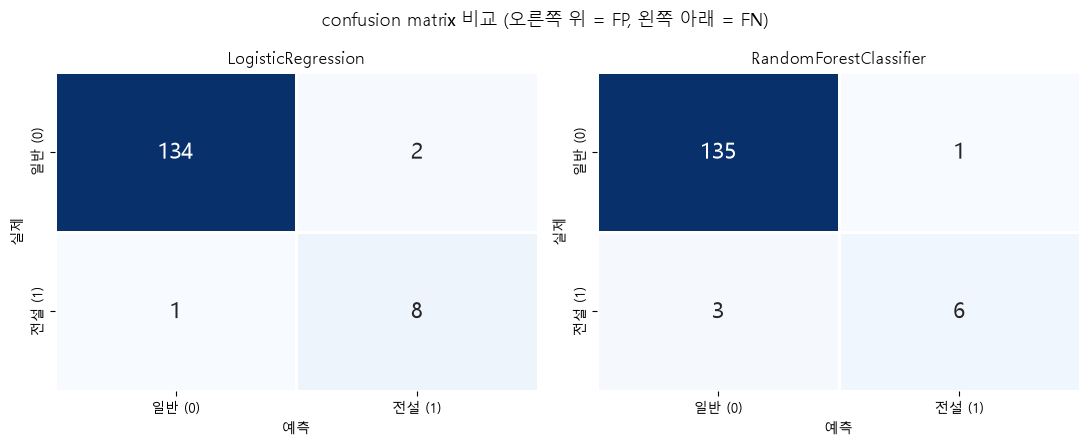

In [12]:
# (추가 분석) 두 모델의 confusion matrix를 히트맵으로 나란히 비교합니다.
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "Malgun Gothic"     # 한글 폰트를 설정합니다.
plt.rcParams["axes.unicode_minus"] = False        # 마이너스 기호가 깨지지 않게 합니다.

labels = ["일반 (0)", "전설 (1)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (name, cm) in zip(axes, [("LogisticRegression", cm_lr), ("RandomForestClassifier", cm_rf)]):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels,
                linewidths=2, linecolor="white", annot_kws={"size": 16}, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("예측")
    ax.set_ylabel("실제")

fig.suptitle("confusion matrix 비교 (오른쪽 위 = FP, 왼쪽 아래 = FN)", fontsize=13)
plt.tight_layout()
plt.show()

### [2-7] 두 모델의 confusion matrix에서 전설 클래스(1)의 **오분류 패턴**을 분석하시오.

- "전설인데 아니라고 한 경우"와 "전설이 아닌데 전설이라고 한 경우"의 개수를 각각 기술하시오.
- (선택) 잘못 분류된 포켓몬의 이름과 능력치를 출력하여, 어떤 특징이 있는지 기술하시오.

In [13]:
# confusion matrix는 [[TN, FP], [FN, TP]] 순서입니다.
rows = []
for name, cm in [("LogisticRegression", cm_lr), ("RandomForestClassifier", cm_rf)]:
    tn, fp, fn, tp = cm.ravel()
    rows.append({"모델": name,
                 "전설인데 아니라고 한 경우 (FN)": fn,
                 "전설이 아닌데 전설이라고 한 경우 (FP)": fp})

display(pd.DataFrame(rows))

# (선택) 잘못 분류된 포켓몬을 확인합니다.
cols = ["Name", "isLegendary",
        "HP", "Attack", "Defense", "Sp_Atk", "Sp_Def", "Speed", "Total",   # 능력치 6개와 합계입니다.
        "Catch_Rate", "Egg_Group_1", "hasGender"]
test_info = df.loc[X_test.index, cols]

for name, pred in [("LogisticRegression", pred_lr), ("RandomForestClassifier", pred_rf)]:
    wrong = test_info[pred != y_test].copy()
    wrong.insert(1, "예측", pred[pred != y_test])
    print(f"[{name}] 잘못 분류된 포켓몬")
    display(wrong)

,모델,전설인데 아니라고 한 경우 (FN),전설이 아닌데 전설이라고 한 경우 (FP)
0,LogisticRegression,1,2
1,RandomForestClassifier,3,1


[LogisticRegression] 잘못 분류된 포켓몬


,Name,예측,isLegendary,HP,Attack,Defense,Sp_Atk,Sp_Def,Speed,Total,Catch_Rate,Egg_Group_1,hasGender
375,Metagross,1,False,80,135,130,95,90,70,600,3,Mineral,False
384,Jirachi,0,True,100,100,100,100,100,100,600,3,Undiscovered,False
250,Celebi,1,False,100,100,100,100,100,100,600,45,Undiscovered,False


[RandomForestClassifier] 잘못 분류된 포켓몬


,Name,예측,isLegendary,HP,Attack,Defense,Sp_Atk,Sp_Def,Speed,Total,Catch_Rate,Egg_Group_1,hasGender
490,Darkrai,0,True,70,90,90,135,90,125,600,3,Undiscovered,False
379,Latias,0,True,80,80,90,110,130,110,600,3,Undiscovered,True
487,Cresselia,1,False,120,70,120,75,130,85,600,3,Undiscovered,True
491,Shaymin,0,True,100,100,100,100,100,100,600,45,Undiscovered,False


#### (추가 분석) 잘못 분류된 포켓몬의 능력치 비교 그래프

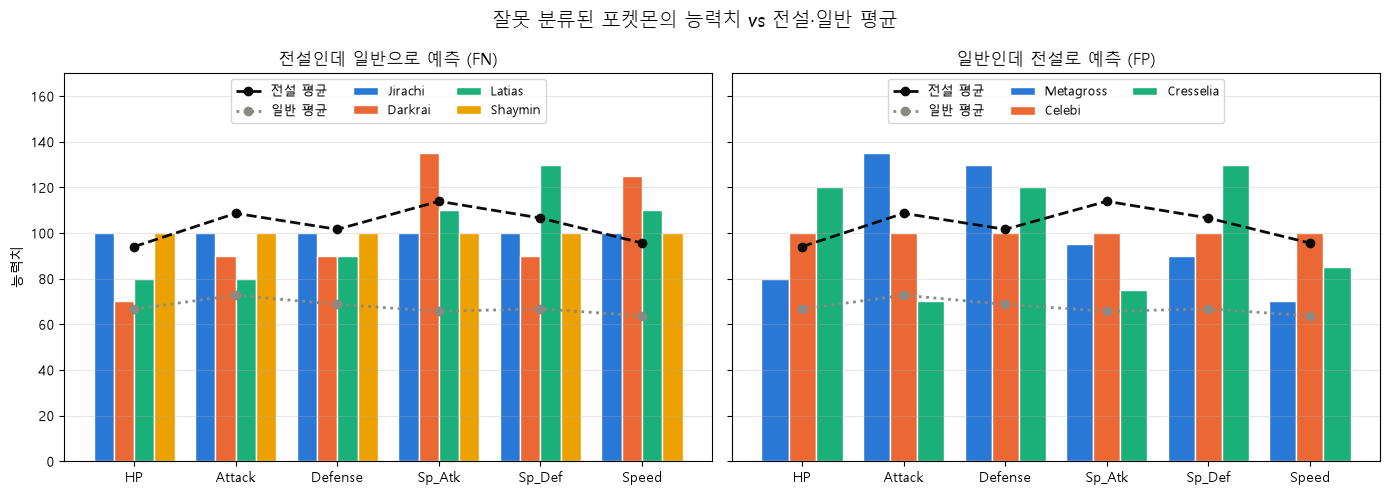

In [14]:
# (추가 분석) 잘못 분류된 포켓몬의 능력치를 전설·일반 평균과 그래프로 비교합니다.
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"     # 한글 폰트를 설정합니다.
plt.rcParams["axes.unicode_minus"] = False        # 마이너스 기호가 깨지지 않게 합니다.

stats = ["HP", "Attack", "Defense", "Sp_Atk", "Sp_Def", "Speed"]

# 비교 기준 : 전설 / 일반 포켓몬의 능력치 평균
legend_mean = df[df["isLegendary"]][stats].mean()
normal_mean = df[~df["isLegendary"]][stats].mean()

# 두 모델에서 잘못 분류된 포켓몬을 FN / FP로 나눕니다.
wrong_names = {
    "전설인데 일반으로 예측 (FN)": ["Jirachi", "Darkrai", "Latias", "Shaymin"],
    "일반인데 전설로 예측 (FP)":   ["Metagross", "Celebi", "Cresselia"],
}
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
x = np.arange(len(stats))

for ax, (title, names) in zip(axes, wrong_names.items()):
    width = 0.8 / len(names)
    for k, name in enumerate(names):
        values = df.loc[df["Name"] == name, stats].iloc[0]
        ax.bar(x - 0.4 + width * (k + 0.5), values, width=width,
               color=colors[k], edgecolor="white", linewidth=1, label=name)

    # 전설 평균, 일반 평균을 선으로 함께 표시합니다.
    ax.plot(x, legend_mean, color="#0b0b0b", ls="--", lw=2, marker="o", label="전설 평균")
    ax.plot(x, normal_mean, color="#8a8984", ls=":", lw=2, marker="o", label="일반 평균")

    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(stats)
    ax.grid(axis="y", alpha=0.3)
    ax.set_ylim(0, 170)                          # 범례가 막대를 가리지 않도록 위쪽 여백을 둡니다.
    ax.legend(fontsize=9, loc="upper center", ncol=3)

axes[0].set_ylabel("능력치")
fig.suptitle("잘못 분류된 포켓몬의 능력치 vs 전설·일반 평균", fontsize=14)
plt.tight_layout()
plt.show()

**두 모델의 오분류 패턴은 다음과 같습니다.**

| 모델 | 전설인데 아니라고 한 경우 (FN) | 전설이 아닌데 전설이라고 한 경우 (FP) |
|---|---|---|
| `LogisticRegression` | 1 (Jirachi) | 2 (Metagross, Celebi) |
| `RandomForestClassifier` | 3 (Darkrai, Latias, Shaymin) | 1 (Cresselia) |

- 잘못 분류된 포켓몬은 모두 **`Total`이 600**이고, 대부분 **`Catch_Rate`가 3**으로 매우 낮으며(나머지 2마리도 45), `Egg_Group_1`이 **`Undiscovered`**(알을 낳지 않음)인 경우가 많았습니다.
- 여섯 능력치를 보면 차이가 더 분명합니다. **Celebi(전설 아님)와 Jirachi, Shaymin(전설)은 여섯 능력치가 모두 100으로 완전히 같습니다.** 능력치가 똑같은데 정답만 다르기 때문에, 능력치만으로는 원래 구분할 수 없는 경우입니다. Metagross는 Attack 135, Defense 130으로 물리 능력치가 전설 평균(Attack 108.6, Defense 101.6)보다 높아서 전설로 잘못 예측된 것으로 보입니다.
- 위 그래프를 보면, 일반으로 예측된 전설(FN)과 전설로 예측된 일반 포켓몬(FP) 모두 대부분의 능력치 막대가 **일반 평균선(점선)보다 훨씬 위, 전설 평균선(파선) 근처**에 있습니다. 즉 잘못 분류된 포켓몬은 능력치만 보면 전설과 일반의 경계에 있는 포켓몬들입니다.
- 따라서 능력치·포획률·알 그룹이 전설과 거의 똑같은 포켓몬들이라 피처만으로는 구분하기 어려웠습니다. (예: Celebi, Cresselia는 전설급이지만 데이터상 전설이 아니고, Metagross는 전설급 능력치를 가진 일반 포켓몬입니다.)
- `LogisticRegression`은 전설을 더 많이 찾아냈고(FN 1), `RandomForestClassifier`는 전설이라고 판단하는 데 더 신중해서 놓친 전설이 더 많았습니다(FN 3).

### [2-8] 두 모델의 성능을 표로 정리하고, 성능 목표 달성 여부를 확인하시오.

**성능 목표**

| 모델 | accuracy | F1 (전설=1) |
| --- | --- | --- |
| `LogisticRegression` | 0.95 이상 | 0.60 이상 |
| `RandomForestClassifier` | 0.95 이상 | 0.60 이상 |

- 2-2에서 구한 기준선과 비교하여, 모델이 의미 있게 학습했는지 기술하시오.
- 두 모델 중 어느 쪽이 더 좋았는지, 그 이유는 무엇일지 기술하시오.

In [15]:
results = pd.DataFrame([
    {"모델": "기준선 (전부 0)",          "accuracy": base_acc, "F1": base_f1},
    {"모델": "LogisticRegression",      "accuracy": acc_lr,   "F1": f1_lr},
    {"모델": "RandomForestClassifier",  "accuracy": acc_rf,   "F1": f1_rf},
]).round(2)

# 목표는 accuracy 0.95 이상, F1 0.60 이상입니다. (기준선은 비교용입니다.)
results["목표 달성"] = np.where(
    results["모델"].str.startswith("기준선"), "-",
    np.where((results["accuracy"] >= 0.95) & (results["F1"] >= 0.60), "O", "X")
)

display(results.set_index("모델"))

,accuracy,F1,목표 달성
모델,,,
기준선 (전부 0),0.94,0.00,-
LogisticRegression,0.98,0.84,O
RandomForestClassifier,0.97,0.75,O


#### (추가 분석) 기준선과 두 모델 성능 비교 그래프

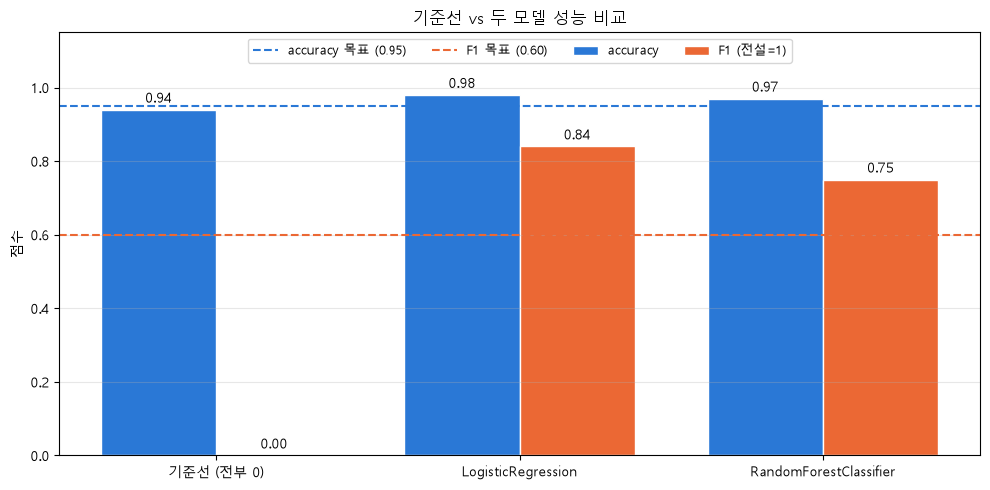

In [16]:
# (추가 분석) 기준선과 두 모델의 accuracy, F1을 목표선과 함께 막대그래프로 비교합니다.
import matplotlib.pyplot as plt

model_names = results["모델"]
x = np.arange(len(model_names))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 5))

bars_acc = ax.bar(x - width / 2, results["accuracy"], width,
                  color="#2a78d6", edgecolor="white", linewidth=1, label="accuracy")
bars_f1 = ax.bar(x + width / 2, results["F1"], width,
                 color="#eb6834", edgecolor="white", linewidth=1, label="F1 (전설=1)")

# 막대 위에 값을 표시합니다.
ax.bar_label(bars_acc, fmt="%.2f", padding=3)
ax.bar_label(bars_f1, fmt="%.2f", padding=3)

# 성능 목표선을 표시합니다.
ax.axhline(0.95, color="#2a78d6", ls="--", lw=1.5, label="accuracy 목표 (0.95)")
ax.axhline(0.60, color="#eb6834", ls="--", lw=1.5, label="F1 목표 (0.60)")

ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.set_ylim(0, 1.15)
ax.set_ylabel("점수")
ax.set_title("기준선 vs 두 모델 성능 비교")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper center", ncol=4, fontsize=9)

plt.tight_layout()
plt.show()

**두 모델의 성능과 목표 달성 여부는 다음과 같습니다.**

| 모델 | accuracy | F1 | 목표 달성 |
|---|---|---|---|
| 기준선 (전부 0) | 0.94 | 0.00 | - |
| `LogisticRegression` | 0.98 | 0.84 | O |
| `RandomForestClassifier` | 0.97 | 0.75 | O |

- **기준선과 비교하면**, accuracy는 0.94에서 0.97~0.98로 조금 올랐지만, F1은 **0.00에서 0.75~0.84로 크게 올랐습니다.** 기준선은 전설을 하나도 찾지 못했지만 두 모델은 검증 데이터의 전설 9마리 중 6~8마리를 찾아냈기 때문에, 의미 있게 학습했다고 볼 수 있습니다.
- 위 그래프를 보면 accuracy 막대는 기준선과 두 모델이 모두 0.94~0.98로 비슷하지만, F1 막대는 기준선 0.00에서 두 모델 모두 목표선(0.60)을 넘어 크게 올라간 것을 한눈에 확인할 수 있습니다.
- **두 모델 중에서는** `LogisticRegression`이 F1 0.84로 더 좋았습니다. 전설 포켓몬은 능력치가 높고 포획률이 낮으며 알 그룹이 `Undiscovered`인 경향이 뚜렷해서, 피처와 전설 여부의 관계가 비교적 단순(선형)하기 때문에 스케일링한 선형 모델로도 경계를 잘 그을 수 있었던 것으로 보입니다. 반면 랜덤포레스트는 학습용 전설 데이터가 37마리로 적어서 트리가 전설 쪽 규칙을 충분히 만들지 못했고, 그 결과 놓친 전설(FN)이 더 많았습니다.

---
## 알게 된 점 / 어려웠던 점

**알게 된 점**
- 모든 포켓몬을 "전설 아님"으로 예측해도 accuracy가 0.94가 나와서, 불균형한 데이터에서는 accuracy보다 F1을 함께 봐야 한다는 것을 직접 확인할 수 있었습니다.
- 잘못 분류된 포켓몬을 직접 확인해 보니 전설과 능력치·포획률이 거의 같은 포켓몬들이어서, 성능 숫자만 보지 않고 틀린 데이터를 직접 살펴보는 것이 필요하다고 느꼈습니다.

**어려웠던 점**
- `Pr_Male`의 결측치를 평균으로 채우면 성별이 없는 포켓몬이 "수컷일 확률 55%"가 되어 버려서, 결측의 의미를 살리면서 어떤 값으로 채울지 정하는 것이 어려웠습니다.
- 일반적으로 더 복잡한 RandomForest가 성능이 좋을 거라고 예상했는데 LogisticRegression의 F1이 더 높게 나와서, 그 이유를 데이터 특징(전설 포켓몬의 뚜렷한 경향, 적은 전설 데이터 수)에서 찾아보는 과정이 어려웠습니다.